# Illustration of the Central Limit Theorem 

The average of several independently distributed random varibles tends to a Gaussian distribution, no matter the underlying distributions.

# Illustration of the Central Limit Theorem 

Let's sample 10000 points from a uniform distribution in $[-1,1]$ and plot the empirical density.

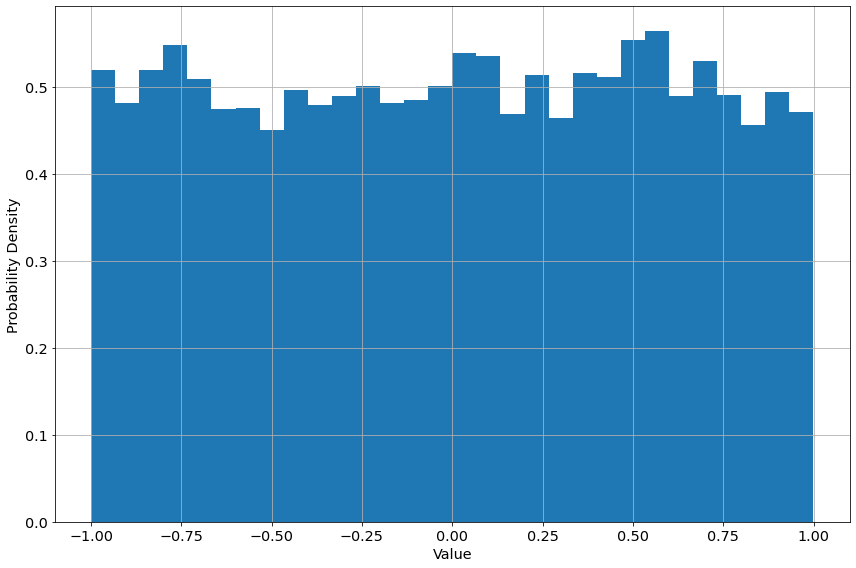

In [10]:
import numpy as np 
import matplotlib.pyplot as plt

numtrials = 10000
samples = np.random.uniform(-1,1,numtrials)

fig, ax = plt.subplots()
N, bins, _ = ax.hist(samples,30,density=True)
ax.set(ylabel='Probability Density',xlabel='Value')
fig.tight_layout(); plt.grid(); plt.show()

# Illustration of the Central Limit Theorem 

Let's sample 10000 points created by averaging $n$ points, each sampled from a uniform distribution in $[-1,1]$, and plot the empirical density.

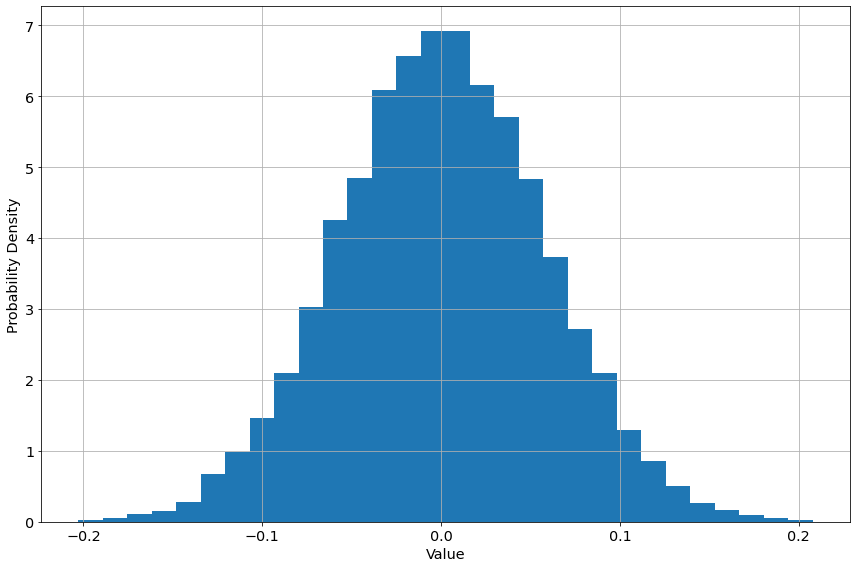

In [17]:
numtrials = 10000
n = 100 # increase me and watch the magic happen!
samples = np.mean(np.random.uniform(-1,1,(numtrials,n)),axis=1)

fig, ax = plt.subplots()
N, bins, _ = ax.hist(samples,30,density=True)
ax.set(ylabel='Probability Density',xlabel='Value')
fig.tight_layout(); plt.grid(); plt.show()

# Illustration of the Central Limit Theorem 

Let's sample 10000 points created by averaging $n$ points, each sampled from an exponential distribution with parameter $\beta = 1/\lambda$, and plot the empirical density.

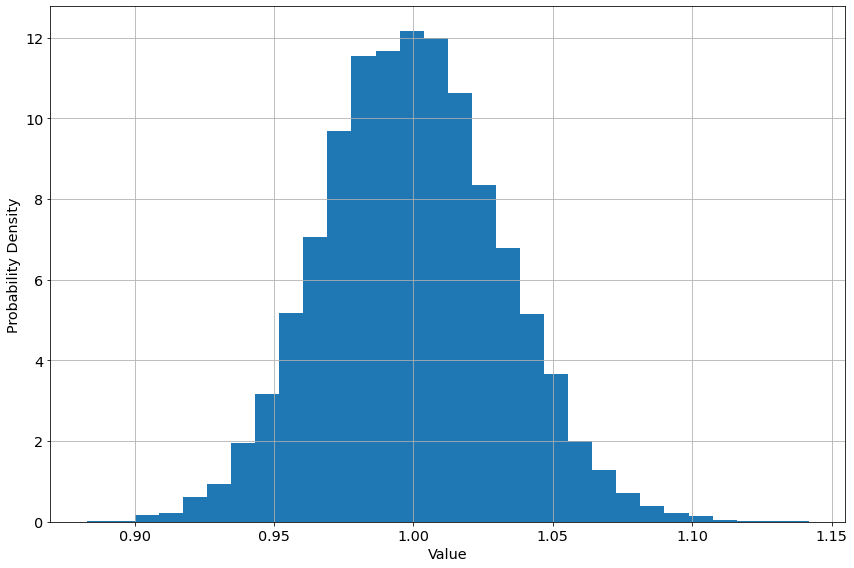

In [22]:
numtrials = 10000
n = 1000 # increase me and watch the magic happen!
lamb = 1
samples = np.mean(np.random.exponential(1/lamb,(numtrials,n)),axis=1)

fig, ax = plt.subplots()
N, bins, _ = ax.hist(samples,30,density=True)
ax.set(ylabel='Probability Density',xlabel='Value')
fig.tight_layout(); plt.grid(); plt.show()

# Illustration of the Central Limit Theorem 

Let's sample 10000 points created by averaging $n$ points, half of which are sampled from an exponential distribution with parameter $\beta = 1/\lambda$, and the other half sampled from a uniform distribution in $[-1,1]$, and plot the empirical density.

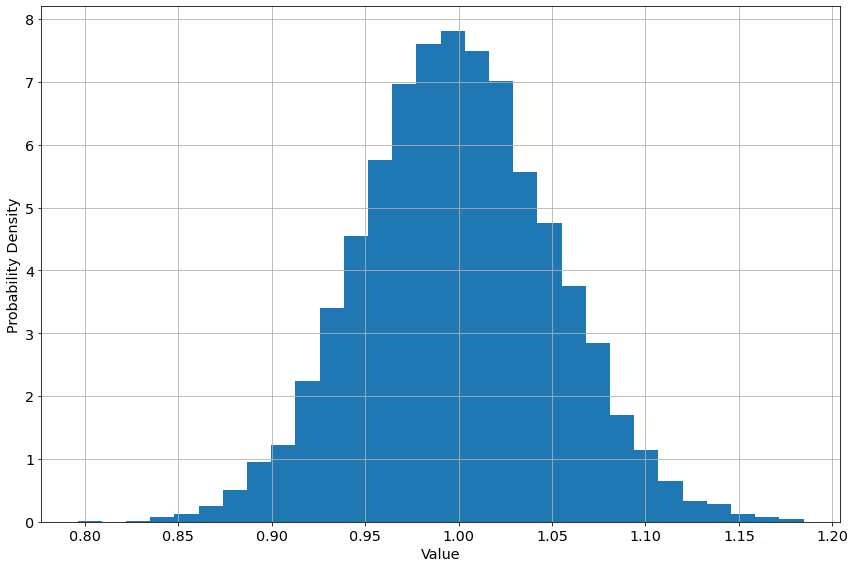

In [26]:
numtrials = 10000
n = 1000 # increase me (even) and watch the magic happen!
lamb = 1
samples = np.mean(np.random.uniform(-1,1,(numtrials,int(n/2))) + \
                np.random.exponential(1/lamb,(numtrials,int(n/2))),axis=1)

fig, ax = plt.subplots()
N, bins, _ = ax.hist(samples,30,density=True)
ax.set(ylabel='Probability Density',xlabel='Value')
fig.tight_layout(); plt.grid(); plt.show()

# Simulate the Quincunx

Let's simulate a quincunx. Here's a schematic drawn by the inventor, Sir Francis Galton:

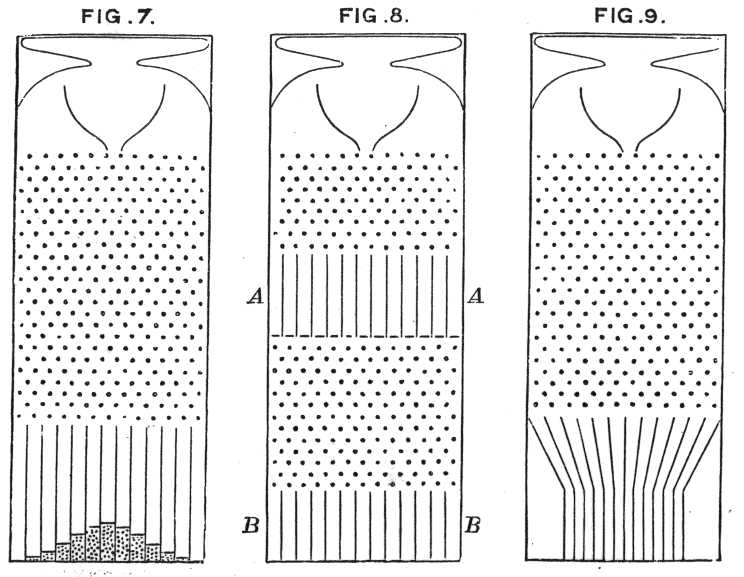

A bead falls from the top receptacle to one of the receptacles at bottom, striking several pegs along the way. When the bead strikes a peg, it moves to the left or right with equal probability. Where is the bead likely to land?

We plot the distribution of 10000 beads ending up in 41 receptacles for a quincunx having 20 rows of pegs.

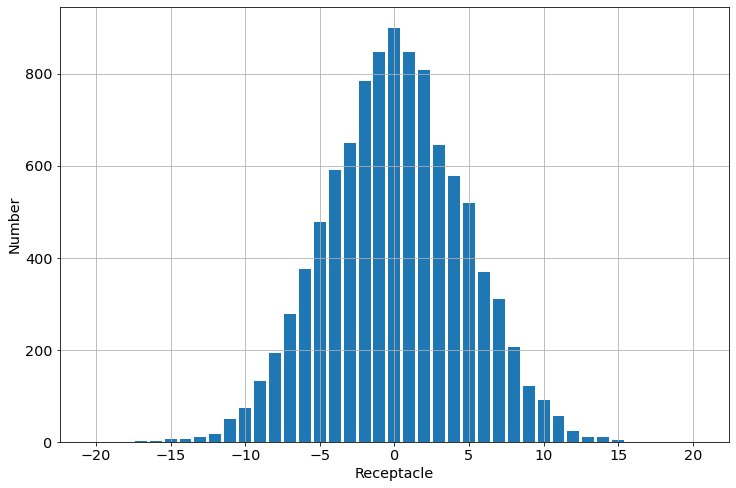

In [30]:
numbeads = 10000
numpegrows = 20
numreceptacles = 41

N = np.zeros(numreceptacles)

for bb in range(numbeads):
    # falling bead chooses one of three starting pegs
    beadpos = np.int(np.round(2*np.random.random_sample())-1) 
    for pp in range(numpegrows):
        if np.random.random_sample() > 0.5:
            beadpos += 1
        else:
            beadpos -= 1
        if beadpos < -(numreceptacles-1)/2:
            beadpos = np.int(-(numreceptacles-1)/2)
        if beadpos > (numreceptacles-1)/2:
            beadpos = np.int((numreceptacles-1)/2)
    N[beadpos+np.int((numreceptacles-1)/2)]+= 1

# The following makes the plot look nice
params = {'legend.fontsize': 'x-large','figure.figsize': (12, 8),
         'axes.labelsize': 'x-large','axes.titlesize':'x-large',
         'xtick.labelsize':'x-large','ytick.labelsize':'x-large'}
plt.rcParams.update(params)

# make a scatter plot of the dataset
fig, ax = plt.subplots()
plt.bar(np.arange(numreceptacles)-(numreceptacles-1)/2,N)
plt.xlabel('Receptacle'); plt.ylabel('Number')
plt.grid()
plt.show()